Best route: [4, np.int64(1), np.int64(6), np.int64(9), np.int64(7), np.int64(2), np.int64(8), np.int64(3), np.int64(5), np.int64(0), 4]
Best distance: 290.31


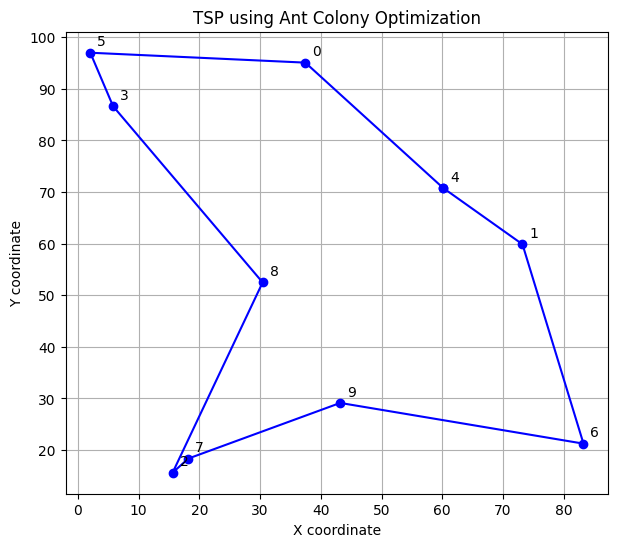

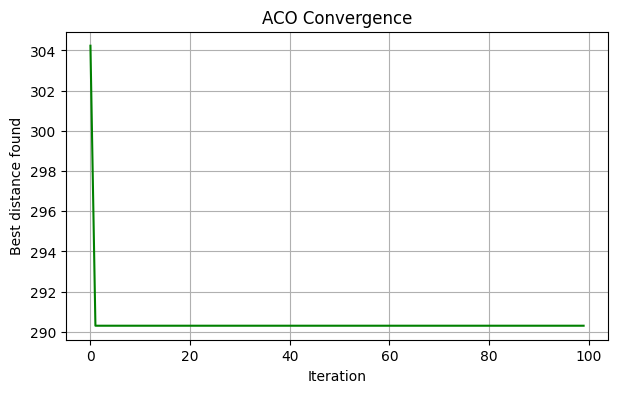

In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate cities
n_cities = 10
cities = np.random.uniform(0, 100, (n_cities, 2))

# ACO parameters
n_ants = 20
iterations = 100
alpha = 1.0
beta = 5.0
rho = 0.5
Q = 100

# Distance matrix
dist = np.linalg.norm(
    cities[:, None, :] - cities[None, :, :], axis=2
)
np.fill_diagonal(dist, np.inf)

# Heuristic information and pheromone
heuristic = 1.0 / dist
pheromone = np.ones((n_cities, n_cities))

best_route = None
best_length = np.inf
history = []

for iteration in range(iterations):
    all_routes = []
    all_lengths = []

    for ant in range(n_ants):
        start = np.random.randint(n_cities)
        route = [start]
        unvisited = set(range(n_cities))
        unvisited.remove(start)

        # Construct a complete tour
        while unvisited:
            current = route[-1]
            candidates = np.array(sorted(unvisited))

            weights = (
                pheromone[current, candidates] ** alpha
                * heuristic[current, candidates] ** beta
            )
            probabilities = weights / weights.sum()

            next_city = np.random.choice(
                candidates, p=probabilities
            )
            route.append(next_city)
            unvisited.remove(next_city)

        # Return to the starting city
        route.append(start)
        length = sum(
            dist[route[i], route[i + 1]]
            for i in range(n_cities)
        )

        all_routes.append(route)
        all_lengths.append(length)

        if length < best_length:
            best_length = length
            best_route = route.copy()

    # Evaporate pheromones
    pheromone *= (1 - rho)

    # Deposit pheromones based on tour quality
    for route, length in zip(all_routes, all_lengths):
        deposit = Q / length
        for i in range(n_cities):
            a, b = route[i], route[i + 1]
            pheromone[a, b] += deposit
            pheromone[b, a] += deposit

    history.append(best_length)

# Display results
print("Best route:", best_route)
print(f"Best distance: {best_length:.2f}")

# Plot best tour
route_cities = cities[best_route]

plt.figure(figsize=(7, 6))
plt.plot(
    route_cities[:, 0], route_cities[:, 1],
    "b-o", markersize=6
)

for i, (x, y) in enumerate(cities):
    plt.annotate(str(i), (x, y), xytext=(5, 5),
                 textcoords="offset points")

plt.title("TSP using Ant Colony Optimization")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.show()

# Plot convergence
plt.figure(figsize=(7, 4))
plt.plot(history, color="green")
plt.xlabel("Iteration")
plt.ylabel("Best distance found")
plt.title("ACO Convergence")
plt.grid(True)
plt.show()
